# Filtered Back Projection

## Objective

Reconstruct the original phantom from its simulated CT projections using
filtered back projection (FBP).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import iradon, radon

from medimaging.quality.psnr import calculate_psnr
from medimaging.quality.ssim import calculate_ssim
from medimaging.simulation.phantom import create_shepp_logan

## 1. Reference Image

The original phantom is used as the reference image for evaluating the
reconstruction.

In [2]:
phantom = create_shepp_logan(256)

theta = np.linspace(0.0, 180.0, 180, endpoint=False)

sinogram = radon(
    phantom,
    theta=theta,
    circle=True,
)

## 2. Filtered Back Projection

Filtered back projection reconstructs an image from the measured
projections by filtering and back-projecting the projection data.

In [3]:
reconstruction = iradon(
    sinogram,
    theta=theta,
    filter_name="ramp",
    circle=True,
)

In [4]:
print("Original shape:", phantom.shape)
print("Reconstruction shape:", reconstruction.shape)
print("Reconstruction dtype:", reconstruction.dtype)

Original shape: (256, 256)
Reconstruction shape: (256, 256)
Reconstruction dtype: float32


## 3. Visual Comparison

The reconstructed image is compared visually with the original phantom.

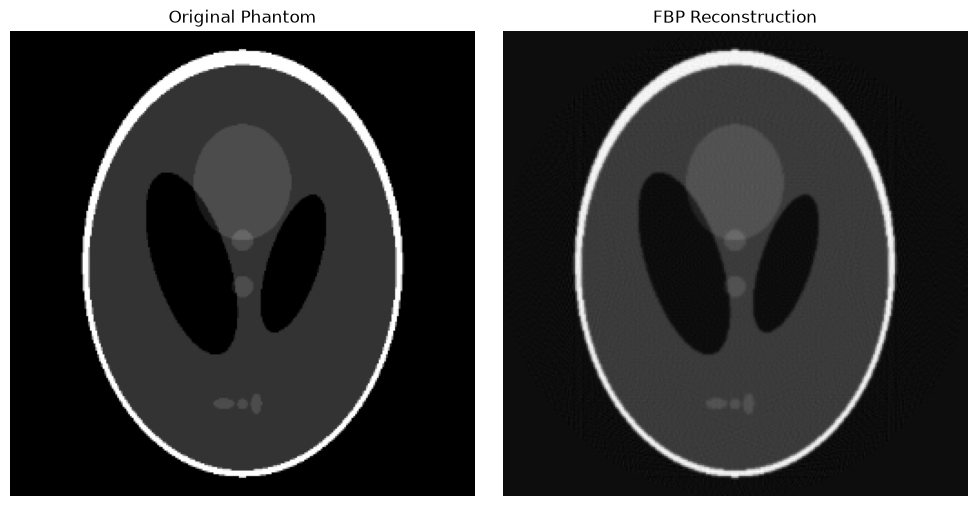

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(phantom, cmap="gray")
axes[0].set_title("Original Phantom")
axes[0].axis("off")

axes[1].imshow(reconstruction, cmap="gray")
axes[1].set_title("FBP Reconstruction")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 4. Image Quality Metrics

We use PSNR and SSIM to quantitatively compare the reconstruction with
the original reference image.

In [6]:
psnr = calculate_psnr(phantom, reconstruction)
print(psnr)

30.774608008018905


In [7]:
ssim = calculate_ssim(phantom, reconstruction)
print(ssim)

0.9218287387086153


## 5. Reconstruction Error

The absolute difference highlights regions where the reconstruction differs
from the reference image.

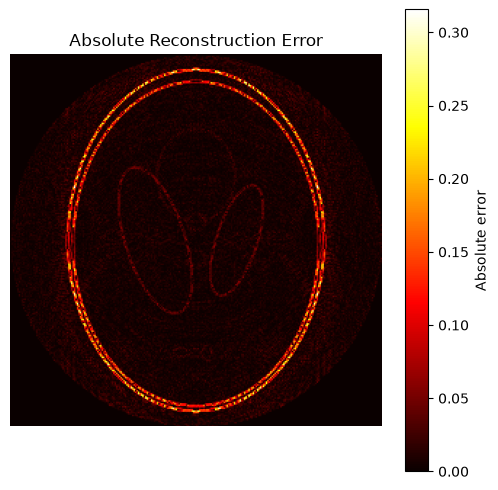

In [8]:
error = np.abs(phantom - reconstruction)

plt.figure(figsize=(6, 6))
plt.imshow(error, cmap="hot")
plt.colorbar(label="Absolute error")
plt.title("Absolute Reconstruction Error")
plt.axis("off")
plt.show()

In [9]:
projection_counts = [30, 60, 120, 180]

results = []

for n_projections in projection_counts:
    theta_test = np.linspace(
        0.0,
        180.0,
        n_projections,
        endpoint=False,
    )

    sinogram_test = radon(
        phantom,
        theta=theta_test,
        circle=True,
    )

    reconstruction_test = iradon(
        sinogram_test,
        theta=theta_test,
        filter_name="ramp",
        circle=True,
    )

    psnr_test = calculate_psnr(phantom, reconstruction_test,)

    ssim_test = calculate_ssim(phantom, reconstruction_test,)

    results.append(
        {
            "projections": n_projections,
            "psnr": psnr_test,
            "ssim": ssim_test,
        }
    )

results

[{'projections': 30, 'psnr': 19.662929647668914, 'ssim': 0.46347741727384995},
 {'projections': 60, 'psnr': 26.729509424049684, 'ssim': 0.6266679678894133},
 {'projections': 120, 'psnr': 30.193884897827882, 'ssim': 0.8504086606010794},
 {'projections': 180, 'psnr': 30.774608008018905, 'ssim': 0.9218287387086153}]

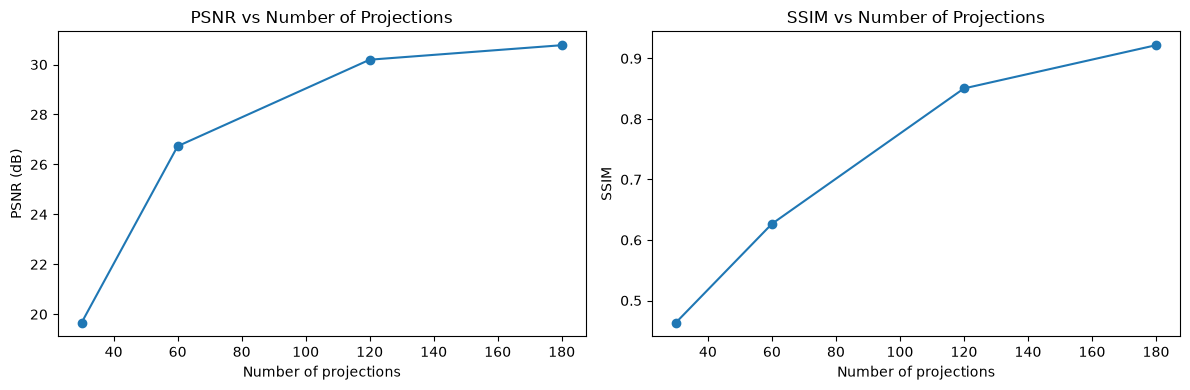

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    [result["projections"] for result in results],
    [result["psnr"] for result in results],
    marker="o",
)

axes[0].set_title("PSNR vs Number of Projections")
axes[0].set_xlabel("Number of projections")
axes[0].set_ylabel("PSNR (dB)")

axes[1].plot(
    [result["projections"] for result in results],
    [result["ssim"] for result in results],
    marker="o",
)

axes[1].set_title("SSIM vs Number of Projections")
axes[1].set_xlabel("Number of projections")
axes[1].set_ylabel("SSIM")

plt.tight_layout()
plt.show()

## 6. Conclusions

Filtered back projection was used to reconstruct the Shepp-Logan phantom
from simulated CT projections.

The reconstruction was evaluated using PSNR and SSIM. The effect of the
number of projection angles was also investigated to study its influence
on reconstruction quality.